![Logo SENATI](../00_Recursos/logo_senati.png)

**SENATI · Laboratorio práctico de IA y visión computacional**  
**Instructor:** Ing. Gunar Castro Iñigo  
**Tecnologías:** Python · OpenCV · NumPy · Matplotlib  
**Modalidad:** demostración → ejecución → interpretación → reto

# Módulo 2 · Fundamentos de detección de objetos

**Propósito:** Localizar dónde está un objeto, delimitarlo y explicar diferencias entre detección y clasificación.

**Actividad completada por:** COCA CCORPA LORENA ABIGAIL.  
**Fuente:** SEMANA 12 TALLER · SENATI.  
Se conservó el nombre original de este cuaderno. Las imágenes son las suministradas por el taller o transformaciones documentadas de ellas.

In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Todos los cuadernos se ejecutan desde su propia carpeta.
RECURSOS = Path('..') / '00_Recursos'
SALIDAS = Path('resultados')
SALIDAS.mkdir(exist_ok=True)

def mostrar(imagen, titulo='Resultado', gris=False):
    """Muestra imágenes en Jupyter sin abrir ventanas externas."""
    plt.figure(figsize=(8, 4))
    if gris:
        plt.imshow(imagen, cmap='gray', vmin=0, vmax=255)
    else:
        plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
    plt.title(titulo)
    plt.axis('off')
    plt.show()

print('Entorno listo. OpenCV:', cv2.__version__)

Entorno listo. OpenCV: 4.13.0


## Explicación
**Clasificar** es decir “hay un círculo”. **Detectar** es decir “hay un círculo aquí”, indicando su posición mediante una caja delimitadora (*bounding box*) o un contorno.

En sistemas modernos, modelos entrenados (como detectores neuronales) aprenden a encontrar objetos variados. Aquí empezaremos con un detector **basado en reglas**, usando el color, para entender la idea antes de usar redes neuronales.

### Ejemplo 1: localizar el objeto verde

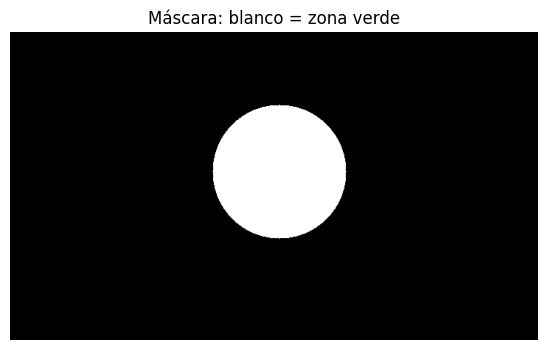

In [2]:
imagen = cv2.imread(str(RECURSOS / 'figuras.png'))
# Convertimos de BGR a HSV: HSV facilita definir rangos de color.
hsv = cv2.cvtColor(imagen, cv2.COLOR_BGR2HSV)
# Separamos los píxeles verdes de los demás.
mascara = cv2.inRange(hsv, np.array([35, 70, 70]), np.array([85, 255, 255]))
mostrar(mascara, 'Máscara: blanco = zona verde', gris=True)

### Ejemplo 2: encerrar el objeto con un rectángulo

Detección en x, y, ancho, alto: 276 99 183 183


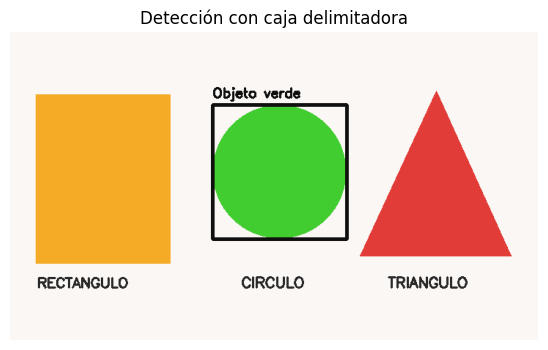

In [3]:
# Los contornos representan los límites de regiones blancas.
contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
resultado = imagen.copy()
for contorno in contornos:
    area = cv2.contourArea(contorno)
    if area < 500:  # Ignoramos regiones demasiado pequeñas.
        continue
    x, y, w, h = cv2.boundingRect(contorno)
    cv2.rectangle(resultado, (x, y), (x+w, y+h), (15, 15, 15), 3)
    cv2.putText(resultado, 'Objeto verde', (x, y-10), cv2.FONT_HERSHEY_SIMPLEX, .6, (15,15,15), 2)
    print('Detección en x, y, ancho, alto:', x, y, w, h)
mostrar(resultado, 'Detección con caja delimitadora')

### Tener en cuenta:
Este método falla si cambia la iluminación o si aparecen otros objetos verdes. No “sabe” que es un círculo; **detecta una región de color**. Las redes neuronales pueden mejorar la generalización, pero requieren datos, entrenamiento y evaluación.

**Reto:** cambia el umbral de área de `500` a `10000`. Explica qué cambia.

**Pregunta de salida:** ¿qué información agrega una caja delimitadora respecto a una clasificación?

<div style="background-color:#FFF0A8;color:#463600;border-left:7px solid #D6A400;padding:14px 18px;border-radius:9px;margin:10px 0 16px"><strong>🟨 INICIO DEL DESARROLLO DE LA ACTIVIDAD</strong><br>Desde aquí se realiza el reto y sus comprobaciones. Se conserva el enunciado original y el código se ejecuta en orden.</div>

### Respuestas cortas

**¿Qué cambia con el umbral 10 000?** En la imagen original sigue apareciendo **1 región**, porque su área supera ambos umbrales. Con objetos pequeños podría descartarlos.  
**¿Qué añade una caja delimitadora?** Indica dónde está el objeto y su tamaño aproximado.

## Ejecución del reto del estudiante (actividad resuelta)

In [4]:
# Reto: cambiar el umbral de área de 500 a 10000 y explicar el impacto.
contornos,_=cv2.findContours(mascara,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
for minimo in [500,10000]:
    filtrados=[c for c in contornos if cv2.contourArea(c)>=minimo]
    salida_umbral=imagen.copy()
    for c in filtrados:
        x,y,w,h=cv2.boundingRect(c)
        cv2.rectangle(salida_umbral,(x,y),(x+w,y+h),(12,10,240),2)
    cv2.imwrite(str(SALIDAS/f'02_umbral_{minimo}.png'),salida_umbral)
    print(f'Umbral {minimo}: {len(filtrados)} regiones detectadas')

Umbral 500: 1 regiones detectadas
Umbral 10000: 1 regiones detectadas


### Conclusión y evaluación

Un umbral mayor descarta objetos pequeños y puede evitar falsos positivos, pero también omitir objetos válidos.

**Evidencia:** ejecutar todas las celdas; las imágenes guardadas en `resultados/` muestran el procesamiento. La captura del cuaderno abierto corresponde al estudiante una vez ejecutado en su máquina.